# 04 Modelos

Escolho o `C`, os hiperparâmetros do Extra Trees e o modelo com uma nested cross-validation, e não nos mesmos folds em que reporto o AUC. Assim, o AUC de cada ano de fora mede o procedimento todo ("escolher e treinar"), e não uma configuração fixa. O Random Forest e o Gradient Boosting entram só como referência.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../task1/best_model")        # as funções que o train.py e o predict também usam
sys.path.insert(0, "../task1/training_code")
import utils, cv, selection

AZUL, VERM, CINZA = "#0072B2", "#D55E00", "#8C8C8C"          # paleta Okabe-Ito, legível por daltónicos
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "figure.figsize": (3.4, 2.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.unicode_minus": False, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def guardar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

In [2]:
raw = pd.read_csv("../data/classification_task1_train.csv", parse_dates=["Date"])
comp = raw[(raw["Year"] < 2020) & raw["CHL"].notna()].copy()      # 2013-2019, só linhas completas; 2020 fica de fora
SPEC = utils.DEFAULT_SPEC
anos = sorted(comp["Year"].unique())
anos_com_hab = [y for y in anos if comp.loc[comp["Year"] == y, "HAB"].nunique() == 2]
cands = selection.candidates()
n_lr = sum(c["family"] == "Logistic Regression" for c in cands.values())
print(f"{len(cands)} candidatos: {n_lr} Logistic Regression (C = {selection.C_GRID}) e {len(cands) - n_lr} Extra Trees")

21 candidatos: 5 Logistic Regression (C = [0.01, 0.1, 1, 10, 100]) e 16 Extra Trees


## 1. O procedimento

Para cada ano de fora (fold exterior), o training set são os outros seis anos. Dentro deles faço um leave-one-year-out (os folds interiores) para escolher o melhor candidato, treino-o nos seis anos e meço o AUC no ano de fora, que nunca influenciou a escolha.

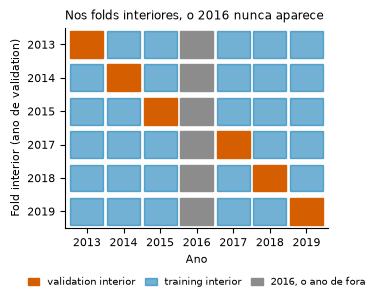

In [3]:
fora = 2016
fig, ax = plt.subplots()
interiores = [a for a in anos if a != fora]
for i, val in enumerate(interiores):
    for j, ano in enumerate(anos):
        cor, alpha = (CINZA, 1) if ano == fora else ((VERM, 1) if ano == val else (AZUL, 0.55))
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.4), 0.9, 0.8, color=cor, alpha=alpha))
ax.set(xlim=(-0.6, len(anos) - 0.4), ylim=(len(interiores) - 0.5, -0.5), xticks=range(len(anos)), yticks=range(len(interiores)),
       xlabel="Ano", ylabel="Fold interior (ano de validation)", title=f"Nos folds interiores, o {fora} nunca aparece")
ax.set_xticklabels(anos); ax.set_yticklabels(interiores); ax.grid(False)
ax.legend(handles=[Patch(color=VERM, label="validation interior"), Patch(color=AZUL, alpha=0.55, label="training interior"),
                   Patch(color=CINZA, label=f"{fora}, o ano de fora")], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3,
          fontsize=7, columnspacing=1.0, handlelength=1.2)
guardar(fig, "13_nested_cv")

Os candidatos são 5 Logistic Regression (C de 0.01 a 100) e 16 Extra Trees (min_samples_leaf, max_features e class_weight), todos com 1000 árvores e a semente 0. Escolho pelo AUC médio por ano nos folds interiores, e em caso de empate fica o primeiro da lista. As features estão fixas (notebook 02): essas decisões foram tomadas com a cross-validation toda, por isso o nested não as cobre.

O `selection.py` tem o procedimento, e o `train.py` vai usar o mesmo.

## 2. Os resultados

O AUC de cada ano de fora, para cada família com o candidato que os folds interiores escolheram, e para a regra que escolhe também a família pelo AUC interior.

In [4]:
auc, agrupado, escolhas = selection.nested(comp, cands)       # o procedimento todo, em cada ano de fora

In [5]:
FAMILIAS = ["Logistic Regression", "Extra Trees"]
nomes = {"Logistic Regression": "Logistic Regression", "Extra Trees": "Extra Trees", "choice": "escolher a família pelo AUC interior"}

def tabela(auc, agrupado):
    t = auc.dropna()[FAMILIAS + ["choice"]].T.rename(index=nomes)
    t["média por ano"] = t.mean(axis=1)
    t["agrupado"] = agrupado[FAMILIAS + ["choice"]].rename(index=nomes)
    return t.round(3)

base_sc = {**SPEC, "SST": False, "UI": False, "CHL": None, "unc": None}      # sazonalidade + cluster, a baseline do notebook 03
a_base, oof_base = cv.loyo(comp, lambda tr, va: utils.score(utils.fit_logreg(tr, base_sc), va))
linha_base = pd.DataFrame([{**a_base.dropna().to_dict(), "média por ano": a_base.mean(), "agrupado": cv.pooled_auc(comp, oof_base)}],
                          index=["sazonalidade + cluster (sem escolher nada)"]).round(3)
aninhado = pd.concat([linha_base, tabela(auc, agrupado)])
aninhado

,2013,2015,2016,2018,2019,média por ano,agrupado
sazonalidade + cluster (sem escolher nada),0.649,0.693,0.821,0.899,0.825,0.778,0.804
Logistic Regression,0.673,0.773,0.835,0.898,0.765,0.789,0.788
Extra Trees,0.697,0.660,0.817,0.901,0.780,0.771,0.718
escolher a família pelo AUC interior,0.673,0.660,0.817,0.898,0.780,0.766,0.742


In [6]:
picks = escolhas.rename(columns={"choice": "escolha final"})
picks.columns = [c.replace("Logistic Regression", "LR").replace("Extra Trees", "ET") for c in picks.columns]
picks.map(lambda s: s.replace("Logistic Regression, ", "").replace("Extra Trees, ", ""))

,ET,LR,escolha final
year,,,
2013,"leaf=5, features=sqrt, weights=none",C=100,C=100
2014,"leaf=5, features=sqrt, weights=none",C=1,"leaf=5, features=sqrt, weights=none"
2015,"leaf=1, features=sqrt, weights=balanced",C=10,"leaf=1, features=sqrt, weights=balanced"
2016,"leaf=3, features=sqrt, weights=none",C=0.01,"leaf=3, features=sqrt, weights=none"
2017,"leaf=3, features=0.5, weights=none",C=10,"leaf=3, features=0.5, weights=none"
2018,"leaf=10, features=sqrt, weights=balanced",C=10,C=10
2019,"leaf=1, features=0.5, weights=none",C=0.1,"leaf=1, features=0.5, weights=none"


A Logistic Regression com o C escolhido nos folds interiores dá 0.789 por ano e 0.788 agrupado nos anos de fora. O Extra Trees dá 0.771 e 0.718. Escolher a família pelo AUC interior dá 0.766 e 0.742, o pior dos três, e abaixo da baseline sazonalidade + cluster (0.778 por ano e 0.804 agrupado), que não escolhe nada.

O Extra Trees tem a melhor nota interior, mas perde nos anos de fora porque escolher entre 16 configurações é ruído: cada fold exterior escolhe outra (min_samples_leaf de 1 a 10, com e sem pesos). A logística também escolhe C muito diferentes (de 0.01 a 100), e os dois anos em que desce mais face à cross-validation simples (2016 e 2019) são aqueles em que o fold interior escolheu C = 0.01 e C = 0.1.

Em 5 dos 7 folds exteriores a regra "melhor AUC interior" escolhe o Extra Trees, e é essa escolha que perde.

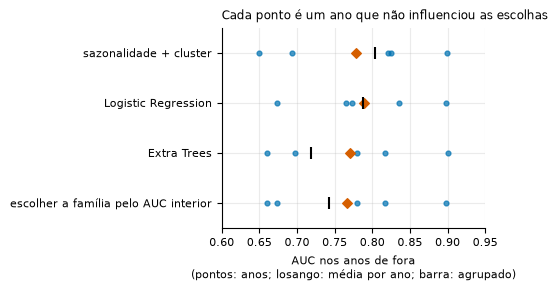

In [7]:
anos_col = [c for c in aninhado.columns if isinstance(c, int)]
fig, ax = plt.subplots()
for i, (nome, linha) in enumerate(aninhado.iterrows()):
    ax.scatter(linha[anos_col].astype(float), [i] * len(anos_col), color=AZUL, s=12, alpha=0.7, zorder=3)
    ax.scatter(linha["média por ano"], i, color=VERM, marker="D", s=24, zorder=4)
    ax.scatter(linha["agrupado"], i, color="k", marker="|", s=70, zorder=4)
ax.set(yticks=range(len(aninhado)), yticklabels=[n.replace(" (sem escolher nada)", "") for n in aninhado.index], xlim=(0.6, 0.95),
       ylim=(len(aninhado) - 0.5, -0.5), xlabel="AUC nos anos de fora\n(pontos: anos; losango: média por ano; barra: agrupado)",
       title="Cada ponto é um ano que não influenciou as escolhas")
guardar(fig, "14_modelos_aninhado")

## 3. A escolha final

O mesmo passo interior, agora nos 7 anos de 2013-2019, dá o melhor candidato de cada família.

In [8]:
tabela_final = selection.select(comp, cands)               # o mesmo passo interior, agora nos 7 anos
melhor_por_familia, melhor = selection.best_of(tabela_final)
familia_final = auc[FAMILIAS].mean().idxmax()          # a família com maior AUC aninhado
candidato_final = melhor_por_familia[familia_final]       # e, dentro dela, o candidato da cross-validation interior
print("melhor de cada família:", melhor_por_familia)
print(f"a regra ingénua (melhor AUC interior) escolheria: {melhor}")
print(f"a regra pelo AUC aninhado escolhe: {candidato_final}")
tabela_final.sort_values("inner_auc", ascending=False).head(8).rename(columns={"family": "família", "inner_auc": "AUC médio por ano"}).round(3)

melhor de cada família: {'Extra Trees': 'Extra Trees, leaf=5, features=sqrt, weights=none', 'Logistic Regression': 'Logistic Regression, C=100'}
a regra ingénua (melhor AUC interior) escolheria: Extra Trees, leaf=5, features=sqrt, weights=none
a regra pelo AUC aninhado escolhe: Logistic Regression, C=100


,família,AUC médio por ano
candidate,,
"Extra Trees, leaf=5, features=sqrt, weights=none",Extra Trees,0.801
"Extra Trees, leaf=3, features=sqrt, weights=none",Extra Trees,0.798
"Logistic Regression, C=100",Logistic Regression,0.798
"Logistic Regression, C=10",Logistic Regression,0.798
"Logistic Regression, C=1",Logistic Regression,0.794
"Extra Trees, leaf=3, features=0.5, weights=none",Extra Trees,0.794
"Extra Trees, leaf=10, features=0.5, weights=none",Extra Trees,0.789
"Extra Trees, leaf=10, features=0.5, weights=balanced",Extra Trees,0.789


In [9]:
otimismo = pd.DataFrame({"sem aninhar (a melhor da cross-validation)": [tabela_final.loc[melhor_por_familia[f], "inner_auc"] for f in ["Logistic Regression", "Extra Trees"]],
                         "aninhado (anos de fora)": [auc[f].mean() for f in ["Logistic Regression", "Extra Trees"]]},
                        index=["Logistic Regression", "Extra Trees"])
otimismo["diferença"] = otimismo.iloc[:, 1] - otimismo.iloc[:, 0]
otimismo.round(3)

,sem aninhar (a melhor da cross-validation),aninhado (anos de fora),diferença
Logistic Regression,0.798,0.789,-0.009
Extra Trees,0.801,0.771,-0.030


O melhor Extra Trees da cross-validation (min_samples_leaf = 5, max_features raiz quadrada, sem pesos) tem 0.801, e a melhor logística (C = 100) tem 0.798. Mas nos anos de fora a logística desce 0.009 (para 0.789) e o Extra Trees desce 0.030 (para 0.771). A vantagem aparente do Extra Trees era otimismo da escolha.

Decisão: a regra é escolher a família com maior AUC aninhado e, dentro dela, o candidato da cross-validation interior nos 7 anos. Fica a Logistic Regression. Escolher pelo melhor AUC interior daria o Extra Trees, e essa regra é a que perde nos anos de fora.

O `C` que a cross-validation interior escolheu foi 100, mas por um empate de milésimas com C = 10 (0.798 nos dois). O AUC é plano de C = 3 a 100, por isso fico com **C = 5**, a meio do patamar: dá o mesmo AUC e coeficientes mais moderados nos clusters raros (o do cluster 1, que não tem nenhum HAB, é -1.1 com C = 5 e -2.8 com C = 100).

## 4. Diagnóstico: bias ou variance?

Comparo o AUC no training set com o AUC na validation, em cada modelo (secção 13.2 das notas CS4780).

In [10]:
def treino_vs_validacao(nome):
    f = cands[nome]["fit_score"]
    treino, validacao = [], []
    for ano in anos_com_hab:
        tr, va = comp[comp["Year"] != ano], comp[comp["Year"] == ano]
        treino.append(roc_auc_score(tr["HAB"], f(tr, tr)))            # o modelo ajustado em tr, a prever o próprio tr
        validacao.append(roc_auc_score(va["HAB"], f(tr, va)))
    return np.mean(treino), np.mean(validacao)

diag = {fam: treino_vs_validacao(nome) for fam, nome in melhor_por_familia.items()}
pd.DataFrame(diag, index=["AUC no training", "AUC na validation"]).T.round(3)

,AUC no training,AUC na validation
Extra Trees,0.960,0.801
Logistic Regression,0.854,0.798


A Logistic Regression tem 0.854 no training e 0.798 na validation, uma diferença de 0.056. O Extra Trees tem 0.960 e 0.801, uma diferença de 0.159: com poucas linhas por folha, as árvores decoram o training set, e é o modelo com mais variance. O AUC de validation é praticamente o mesmo, mas é o do Extra Trees que não se mantém nos anos de fora quando a escolha entra no procedimento.

## 5. Referência: Random Forest e Gradient Boosting

Sem tuning e fora do nested, só para ter uma referência com as mesmas features.

In [11]:
def arvore_sklearn(modelo):
    def fit_score(tr, va):
        med = utils.fallback_medians(tr)
        return modelo().fit(utils.tree_matrix(tr, med), tr["HAB"]).predict_proba(utils.tree_matrix(va, med))[:, 1]
    return fit_score

def resumo(fit_score, nome):
    a, oof = cv.loyo(comp, fit_score)
    return {"nome": nome, **{int(y): v for y, v in a.dropna().items()}, "média por ano": a.mean(), "agrupado": cv.pooled_auc(comp, oof)}

pd.DataFrame([
    resumo(arvore_sklearn(lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=0)), "Random Forest"),
    resumo(arvore_sklearn(lambda: GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=0)), "Gradient Boosting"),
]).set_index("nome").round(3)

,2013,2015,2016,2018,2019,média por ano,agrupado
nome,,,,,,,
Random Forest,0.599,0.767,0.802,0.878,0.722,0.754,0.741
Gradient Boosting,0.571,0.853,0.725,0.872,0.746,0.753,0.726


O Random Forest dá 0.754 e o Gradient Boosting 0.753 por ano, abaixo da Logistic Regression e do Extra Trees. Na exploração anterior, com 25 combinações sorteadas, deram 0.777 e 0.790 (tabela abaixo). Não os levo adiante.

## 6. O que não ajudou

Exploração anterior, não re-executada. Os números vêm de testes feitos antes de fixar as features (alguns com o log na incerteza) e servem de ordem de grandeza. Todos são leave-one-year-out em 2013-2019 com a Logistic Regression, salvo indicação.

| Técnica | AUC médio por ano | Nota |
|---|---|---|
| Sobreamostragem aleatória | 0.792 | iguala o class_weight, que é mais simples |
| Subamostragem aleatória | 0.783 | deita fora linhas |
| SMOTE (k = 3, 5 e 10) | 0.785 a 0.788 | |
| ADASYN | 0.787 | |
| Borderline-SMOTE | 0.769 | |
| EasyEnsemble (25 e 100 subamostras) | 0.791 a 0.792 | |
| Peso por cluster e classe | 0.736 | apaga o efeito do cluster |
| Penalização L1 (C = 10) e elastic net (C = 3) | 0.795 e 0.797 | |
| Regressão de Firth | 0.774 sem pesos, 0.797 com pesos | |
| SVM com kernel RBF | 0.790 | |
| kNN, LDA, QDA e Naive Bayes | 0.745 a 0.784 | |
| Deteção de anomalias (Isolation Forest, LOF, One-Class SVM, Mahalanobis) | 0.47 a 0.68 | o HAB é um regime sazonal, não um ponto anómalo |
| Random Forest, melhor de 25 combinações | 0.777 | |
| Gradient Boosting e Hist Gradient Boosting, melhor de 25 combinações | 0.790 | |
| WoE, folhas de árvores com logística, hinges e interações | 0.73 a 0.79 | nenhuma passou de 0.80 |
| Rede neuronal (PyTorch, ensemble de 8), com 2020 no training | 0.82, contra 0.799 da logística nesse protocolo | em 2020 não se confirma (0.815 a 0.835 contra 0.864) e não é submissível, porque não há `torch` |

## 7. O que guardo

A escolha final fica em `training_code/config.json`, que o `train.py` vai ler: Logistic Regression, balanced, C = 5.

In [12]:
C_FINAL = 5.0          # o AUC é plano de C = 3 a 100 (o nested escolheu 100 por um empate de milésimas); fico a meio por estabilidade
config = {"selecao": "nested leave-one-year-out; família e C escolhidos com o leave-one-year-out interior nos 7 anos de 2013-2019",
          "modelo_final": familia_final, "candidato": candidato_final, "nested_escolheu": cands[candidato_final]["params"],
          "params": {"C": C_FINAL}, "spec": SPEC,
          "melhor_por_familia": {fam: {"candidato": nome, "params": cands[nome]["params"]} for fam, nome in melhor_por_familia.items()}}
json.dump(config, open("../task1/training_code/config.json", "w"), indent=2)
print("modelo final:", config["modelo_final"], "|", config["candidato"])

modelo final: Logistic Regression | Logistic Regression, C=100


In [13]:
ref = json.load(open("reference_numbers.json"))["LOYO_2013_2019"]
auc_s0, _ = cv.loyo(comp, lambda tr, va: utils.score(utils.fit_logreg(tr, dict(SPEC, unc="log")), va))
auc_et, _ = cv.loyo(comp, lambda tr, va: utils.score_extra_trees(utils.fit_extra_trees(tr, n_estimators=300), va))
print(f"Logistic Regression com log na incerteza: média {auc_s0.mean():.3f} | referência {ref['LR']['media']}")
print(f"Extra Trees da referência (300 árvores, semente 0): média {auc_et.mean():.3f} | referência {ref['ET']['media']}")

Logistic Regression com log na incerteza: média 0.797 | referência 0.797
Extra Trees da referência (300 árvores, semente 0): média 0.805 | referência 0.805


A Logistic Regression com log na incerteza reproduz a referência (0.797), e o Extra Trees da referência (300 árvores, semente 0) também (0.805). Esse 0.805 era a semente mais favorável: com 1000 árvores o AUC médio fica entre 0.797 e 0.799. O `C` fica em 5, como nos notebooks anteriores, e o AUC por ano é 0.798.